In [ ]:

%pip install -q scikit-learn pandas matplotlib seaborn shap

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.inspection import permutation_importance

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth": [3, 5, 8, None]},
    cv=5,
    scoring="accuracy"
)
tree_search.fit(X_train, y_train)
tree = tree_search.best_estimator_

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 200],
        "max_depth": [None, 10],
        "max_features": ["sqrt"]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
rf_search.fit(X_train, y_train)
forest = rf_search.best_estimator_

for name, model in [
    ("Decision Tree", tree),
    ("Random Forest", forest)
]:
    predictions = model.predict(X_test)
    print(f"\n{name}")
    print("Best parameters:",
          tree_search.best_params_ if name == "Decision Tree"
          else rf_search.best_params_)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("F1 score:", round(f1_score(y_test, predictions), 4))

print("\nNumber of trees in Random Forest:",
      forest.n_estimators)


Decision Tree
Best parameters: {'max_depth': 5}
Accuracy: 0.9211
F1 score: 0.9362

Random Forest
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}
Accuracy: 0.9561
F1 score: 0.9655

Number of trees in Random Forest: 200


                         Impurity importance  Permutation importance
compactness error                     0.0046                  0.0088
mean area                             0.0499                  0.0088
worst perimeter                       0.1331                  0.0088
worst area                            0.1281                  0.0079
mean concave points                   0.0944                  0.0079
mean radius                           0.0587                  0.0070
worst texture                         0.0179                  0.0070
worst radius                          0.0906                  0.0070
concave points error                  0.0037                  0.0061
worst concave points                  0.1081                  0.0053
worst fractal dimension               0.0064                  0.0053
mean smoothness                       0.0062                  0.0053
mean perimeter                        0.0552                  0.0044
radius error                      

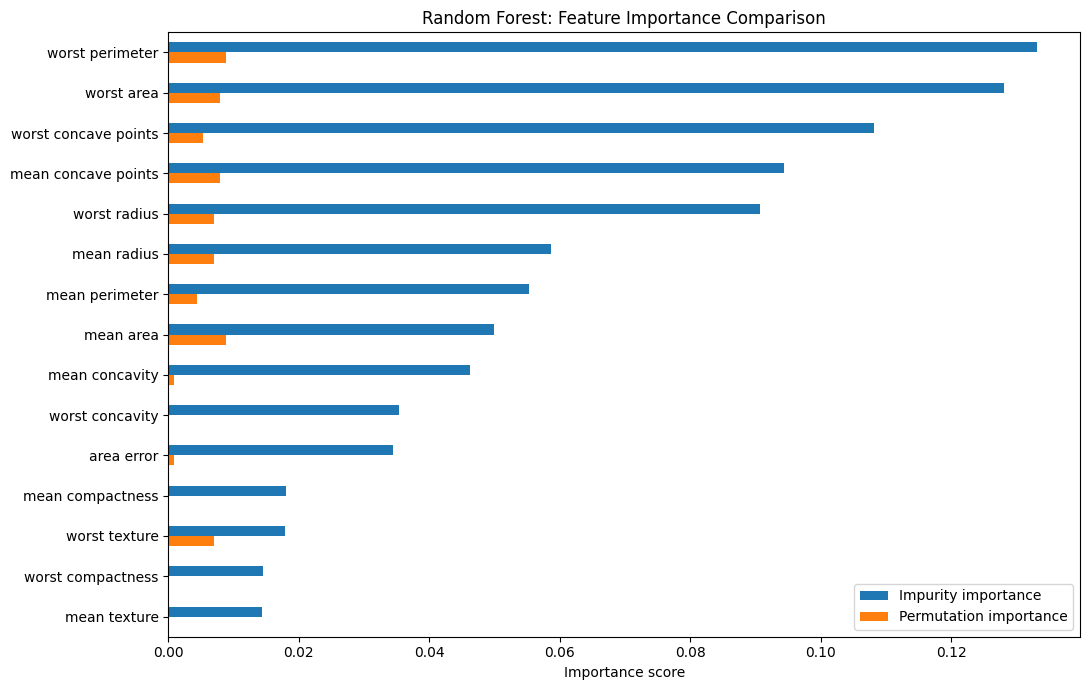

In [ ]:

impurity = pd.Series(
    forest.feature_importances_, index=X.columns
).sort_values(ascending=False)

perm_result = permutation_importance(
    forest, X_test, y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation = pd.Series(
    perm_result.importances_mean, index=X.columns
).sort_values(ascending=False)

comparison = pd.DataFrame({
    "Impurity importance": impurity,
    "Permutation importance": permutation
})

print(comparison.sort_values(
    "Permutation importance", ascending=False
).head(15).round(4))

top_features = comparison.nlargest(
    15, "Impurity importance"
).index

comparison.loc[top_features].plot(
    kind="barh", figsize=(11, 7)
)
plt.title("Random Forest: Feature Importance Comparison")
plt.xlabel("Importance score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

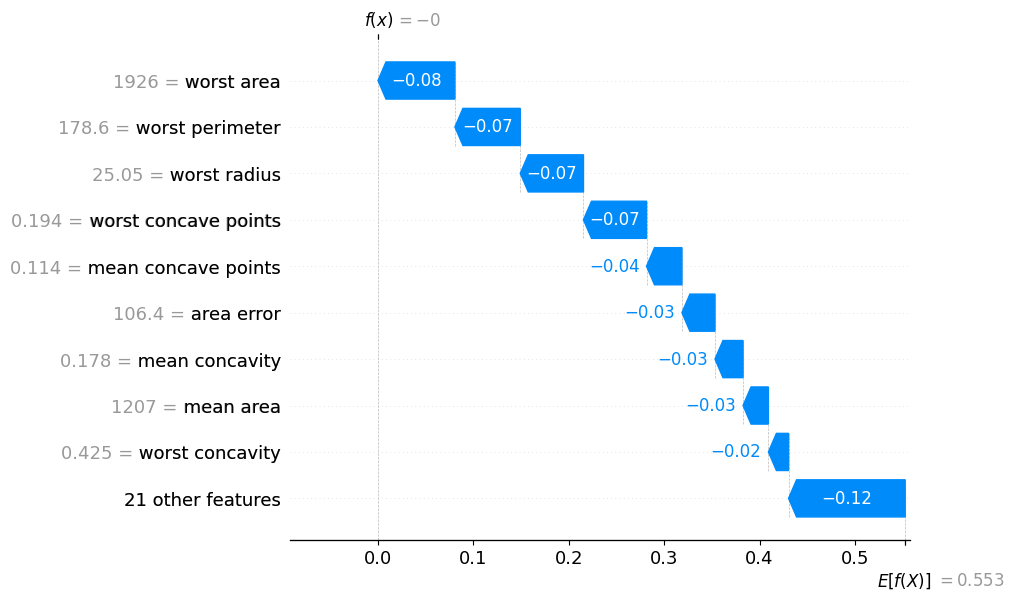

In [ ]:

background = shap.sample(X_train, 50, random_state=42)
examples = X_test.iloc[:5]

explainer = shap.TreeExplainer(
    forest,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

shap_values = explainer(examples)

class_index = list(forest.classes_).index(1)

shap.plots.waterfall(
    shap_values[0, :, class_index],
    max_display=10
)

SHAP explanation for test example 1


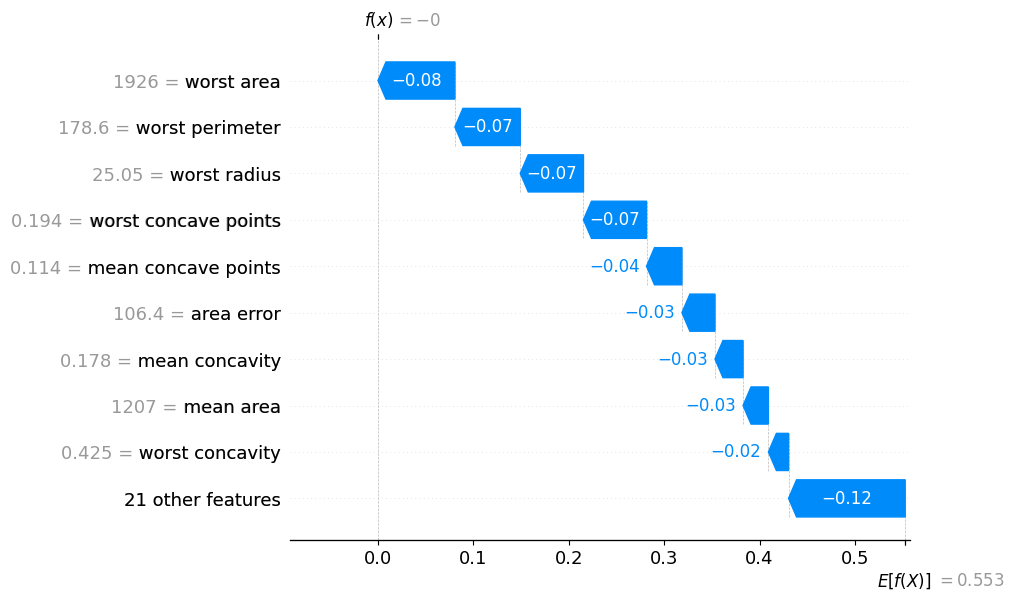

SHAP explanation for test example 2


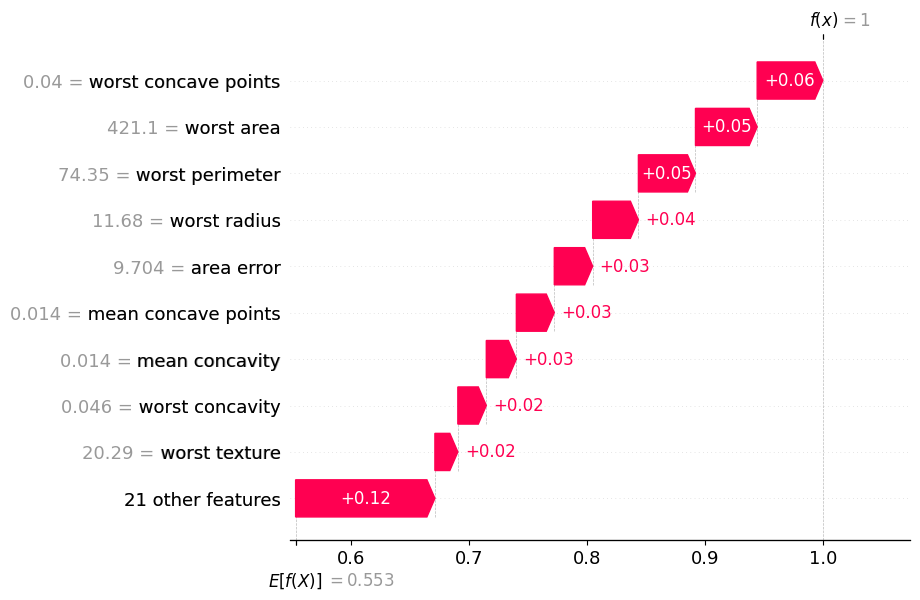

SHAP explanation for test example 3


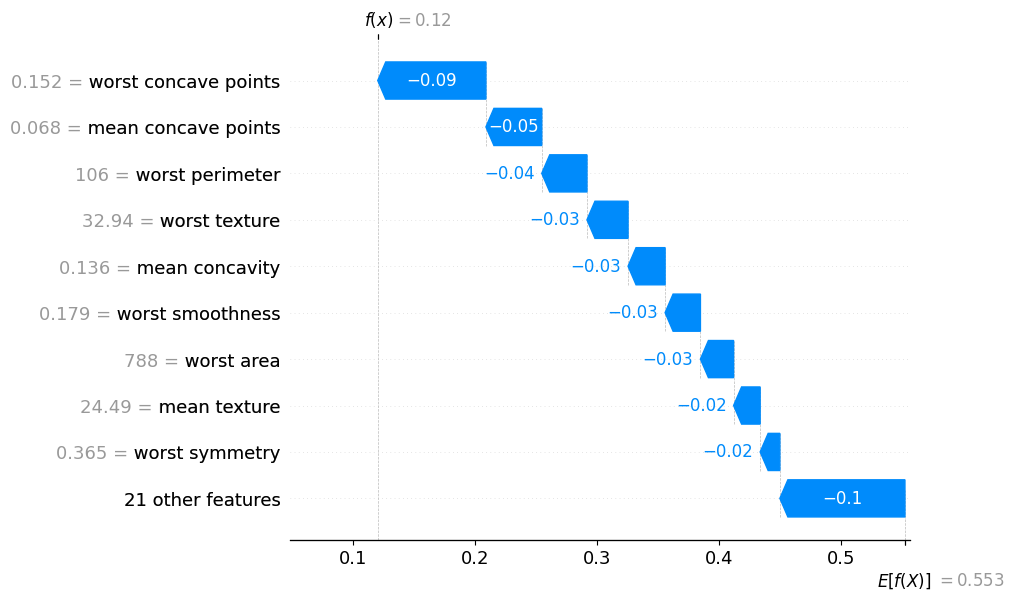

SHAP explanation for test example 4


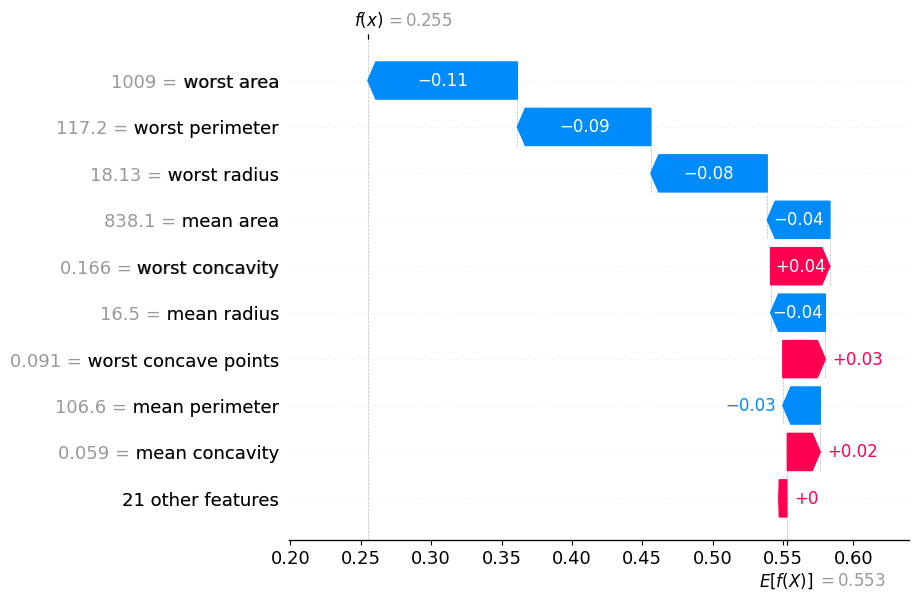

SHAP explanation for test example 5


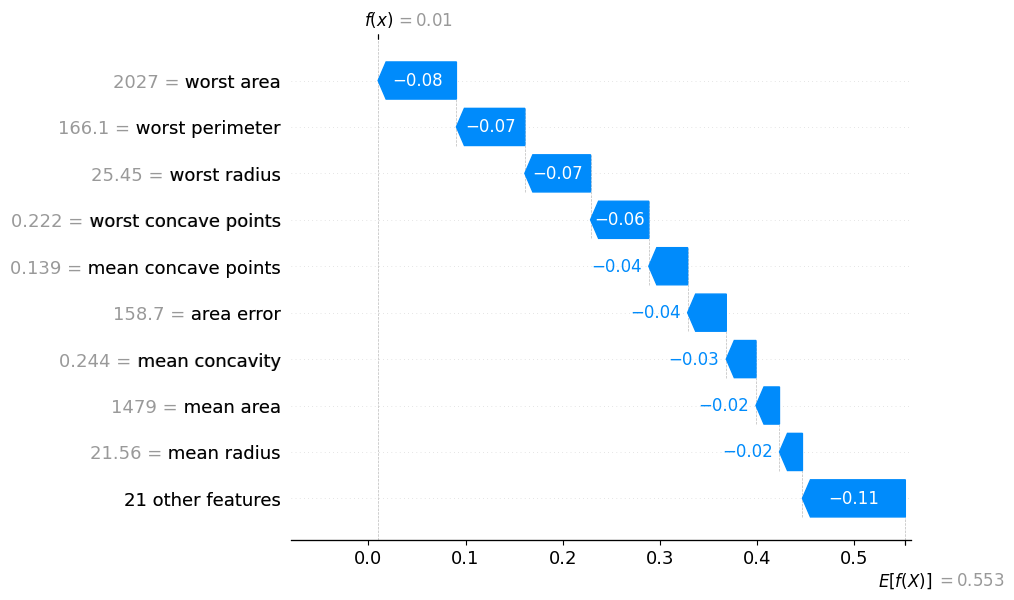

In [ ]:

for i in range(5):
    print(f"SHAP explanation for test example {i + 1}")
    shap.plots.waterfall(
        shap_values[i, :, class_index],
        max_display=10,
        show=True
    )